# Multi-Video Surgical Phase Analysis

This notebook analyzes ALL validation videos and creates beautiful horizontal bar visualizations for the TOP 5 performing videos.

In [1]:
import os
import sys
import numpy as np
from pathlib import Path
import glob

# os.environ['USE_BOUNDARY_POST'] = '1'
# os.environ['BOUNDARY_GAMMA'] = '1.0'
# os.environ['BOUNDARY_WINDOW'] = '1'

# Add the i3d_submission directory to path for model import
sys.path.insert(0, 'i3d_submission_3')
from model import Model

print("✓ Basic libraries imported successfully")
print("✓ Model import path configured")

✓ Basic libraries imported successfully
✓ Model import path configured


In [2]:
# Define surgical phase mapping
PHASE_MAPPING = {
    0: 'background',
    1: 'peritomy',
    2: 'cautery',
    3: 'scleral_groove',
    4: 'incision',
    5: 'tunnel',
    6: 'sideport',
    7: 'AB_injection_and_wash',
    8: 'OVD_injection',
    9: 'capsulorrhexis',
    10: 'main_incision_entry',
    11: 'hydroprocedure',
    12: 'nucleus_prolapse',
    13: 'nucleus_delivery',
    14: 'cortical_wash',
    15: 'OVD_IOL_insertion',
    16: 'OVD_wash',
    17: 'stromal_hydration',
    18: 'tunnel_suture'
}

# Create reverse mapping for text to index
TEXT_TO_INDEX = {v: k for k, v in PHASE_MAPPING.items()}

print(f"✓ Phase mapping loaded with {len(PHASE_MAPPING)} phases")

✓ Phase mapping loaded with 19 phases


In [3]:
# Load the model
print("Loading FACT model...")
model = Model()
print("✓ Model loaded successfully")
print(f"Device: {model.device}")
print(f"Number of classes: {model.num_classes}")

Loading FACT model...
✓ Model loaded successfully
Device: cuda
Number of classes: 19


In [4]:
# Get all validation video files
val_features_dir = 'data/i3d/features/val'
val_gt_dir = 'data/i3d/groundTruth/val'

# Find all .npy files in validation features directory
feature_files = glob.glob(os.path.join(val_features_dir, '*.npy'))
video_ids = [os.path.splitext(os.path.basename(f))[0] for f in feature_files]

print(f"Found {len(video_ids)} validation videos:")
for vid in video_ids:
    print(f"  - {vid}")

print(f"\nWill select TOP 5 performing videos after analysis")

Found 15 validation videos:
  - BL_0105
  - BN_0088
  - BN_0044
  - SD_0305
  - BL_0180
  - SD_0261
  - SD_0314
  - BN_0056
  - BN_0046
  - BN_0013
  - SD_0269
  - BL_0102
  - BL_0143
  - BN_0047
  - BL_0234

Will select TOP 5 performing videos after analysis


In [5]:
# Process all validation videos and collect results
print("Processing all validation videos...")
all_results = {}
overall_metrics = {}

for video_id in video_ids:
    print(f"\nProcessing {video_id}...")
    
    # File paths
    features_path = os.path.join(val_features_dir, f'{video_id}.npy')
    ground_truth_path = os.path.join(val_gt_dir, f'{video_id}.txt')
    
    try:
        # Load features
        features = np.load(features_path)
        if features.shape[1] != 1024:
            features = features.T
        
        # Get predictions
        features_dict = {video_id: features}
        predictions = model.predict(features_dict)
        pred_sequence = predictions[video_id]
        
        # Load ground truth
        with open(ground_truth_path, 'r') as f:
            gt_lines = f.readlines()
        
        gt_sequence = []
        for line in gt_lines:
            line = line.strip()
            if line in TEXT_TO_INDEX:
                gt_sequence.append(TEXT_TO_INDEX[line])
            else:
                gt_sequence.append(0)
        
        gt_sequence = np.array(gt_sequence)
        
        # Align sequences
        min_length = min(len(pred_sequence), len(gt_sequence))
        pred_sequence = pred_sequence[:min_length]
        gt_sequence = gt_sequence[:min_length]
        
        # Calculate metrics
        accuracy = np.mean(pred_sequence == gt_sequence)
        
        # Store results
        all_results[video_id] = {
            'gt_sequence': gt_sequence,
            'pred_sequence': pred_sequence,
            'length': min_length,
            'accuracy': accuracy,
            'gt_phases': np.unique(gt_sequence),
            'pred_phases': np.unique(pred_sequence)
        }
        
        print(f"  ✓ {video_id}: {min_length} frames, accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
        
    except Exception as e:
        print(f"  ✗ {video_id}: Error - {e}")
        continue

print(f"\n✓ Processed {len(all_results)} videos successfully")

Processing all validation videos...

Processing BL_0105...


/home/yasser/miniconda3/envs/fact_new/lib/python3.9/site-packages/torch/nn/functional.py:1542: UserWarning: dropout2d: Received a 3D input to dropout2d and assuming that channel-wise 1D dropout behavior is desired - input is interpreted as shape (N, C, L), where C is the channel dim. This behavior will change in a future release to interpret the input as one without a batch dimension, i.e. shape (C, H, W). To maintain the 1D channel-wise dropout behavior, please switch to using dropout1d instead.
  warnings.warn(


  ✓ BL_0105: 14398 frames, accuracy: 0.7580 (75.80%)

Processing BN_0088...
  ✓ BN_0088: 6013 frames, accuracy: 0.8041 (80.41%)

Processing BN_0044...
  ✓ BN_0044: 5398 frames, accuracy: 0.9544 (95.44%)

Processing SD_0305...
  ✓ SD_0305: 12584 frames, accuracy: 0.8448 (84.48%)

Processing BL_0180...
  ✓ BL_0180: 19304 frames, accuracy: 0.8200 (82.00%)

Processing SD_0261...
  ✓ SD_0261: 8969 frames, accuracy: 0.8940 (89.40%)

Processing SD_0314...
  ✓ SD_0314: 16184 frames, accuracy: 0.7829 (78.29%)

Processing BN_0056...
  ✓ BN_0056: 9901 frames, accuracy: 0.8855 (88.55%)

Processing BN_0046...
  ✓ BN_0046: 8083 frames, accuracy: 0.7484 (74.84%)

Processing BN_0013...
  ✓ BN_0013: 10770 frames, accuracy: 0.8396 (83.96%)

Processing SD_0269...
  ✓ SD_0269: 16467 frames, accuracy: 0.7732 (77.32%)

Processing BL_0102...
  ✓ BL_0102: 9885 frames, accuracy: 0.8543 (85.43%)

Processing BL_0143...
  ✓ BL_0143: 11698 frames, accuracy: 0.9453 (94.53%)

Processing BN_0047...
  ✓ BN_0047: 12594

In [6]:
# Analyze overall performance and select top performers
print("Overall Performance Analysis:")
print("=" * 60)

# Calculate overall statistics
accuracies = [result['accuracy'] for result in all_results.values()]
lengths = [result['length'] for result in all_results.values()]
total_frames = sum(lengths)

print(f"Total videos analyzed: {len(all_results)}")
print(f"Total frames processed: {total_frames:,}")
print(f"Average accuracy: {np.mean(accuracies):.4f} ({np.mean(accuracies)*100:.2f}%)")
print(f"Accuracy std: {np.std(accuracies):.4f}")
print(f"Min accuracy: {np.min(accuracies):.4f} ({np.min(accuracies)*100:.2f}%)")
print(f"Max accuracy: {np.max(accuracies):.4f} ({np.max(accuracies)*100:.2f}%)")
print(f"Average video length: {np.mean(lengths):.0f} frames")

# Sort videos by accuracy and select TOP 5 performers
sorted_videos = sorted(all_results.items(), key=lambda x: x[1]['accuracy'], reverse=True)
selected_videos = [vid for vid, _ in sorted_videos[:5]]

print("\n🎯 TOP 5 performing videos selected for visualization:")
for i, (vid, result) in enumerate(sorted_videos[:5]):
    print(f"  {i+1}. {vid}: {result['accuracy']:.4f} ({result['accuracy']*100:.2f}%)")

print("\nBottom performing videos:")
for i, (vid, result) in enumerate(sorted_videos[-5:]):
    print(f"  {len(sorted_videos)-i}. {vid}: {result['accuracy']:.4f} ({result['accuracy']*100:.2f}%)")

# Phase analysis
print("\nPhase coverage analysis:")
all_gt_phases = set()
all_pred_phases = set()
for result in all_results.values():
    all_gt_phases.update(result['gt_phases'])
    all_pred_phases.update(result['pred_phases'])

print(f"  Ground truth phases found: {sorted(all_gt_phases)}")
print(f"  Predicted phases: {sorted(all_pred_phases)}")
print(f"  Missing predictions: {set(all_gt_phases) - set(all_pred_phases)}")
print(f"  Extra predictions: {set(all_pred_phases) - set(all_gt_phases)}")

Overall Performance Analysis:
Total videos analyzed: 15
Total frames processed: 177,366
Average accuracy: 0.8410 (84.10%)
Accuracy std: 0.0608
Min accuracy: 0.7484 (74.84%)
Max accuracy: 0.9544 (95.44%)
Average video length: 11824 frames

🎯 TOP 5 performing videos selected for visualization:
  1. BN_0044: 0.9544 (95.44%)
  2. BL_0143: 0.9453 (94.53%)
  3. SD_0261: 0.8940 (89.40%)
  4. BN_0056: 0.8855 (88.55%)
  5. BL_0234: 0.8788 (87.88%)

Bottom performing videos:
  15. BN_0088: 0.8041 (80.41%)
  14. SD_0314: 0.7829 (78.29%)
  13. SD_0269: 0.7732 (77.32%)
  12. BL_0105: 0.7580 (75.80%)
  11. BN_0046: 0.7484 (74.84%)

Phase coverage analysis:
  Ground truth phases found: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]
  Predicted phases: [np.int64(0), np.int64(1), np.int64(2), np.

In [7]:
# ...existing code...
# Analyze overall performance and select top performers
print("Overall Performance Analysis:")
print("=" * 60)

# Calculate overall statistics
accuracies = [result['accuracy'] for result in all_results.values()]
lengths = [result['length'] for result in all_results.values()]
total_frames = sum(lengths)

print(f"Total videos analyzed: {len(all_results)}")
print(f"Total frames processed: {total_frames:,}")
print(f"Average accuracy: {np.mean(accuracies):.4f} ({np.mean(accuracies)*100:.2f}%)")
print(f"Accuracy std: {np.std(accuracies):.4f}")
print(f"Min accuracy: {np.min(accuracies):.4f} ({np.min(accuracies)*100:.2f}%)")
print(f"Max accuracy: {np.max(accuracies):.4f} ({np.max(accuracies)*100:.2f}%)")
print(f"Average video length: {np.mean(lengths):.0f} frames")

# Sort videos by accuracy and select TOP 5 performers
sorted_videos = sorted(all_results.items(), key=lambda x: x[1]['accuracy'], reverse=True)
selected_videos = [vid for vid, _ in sorted_videos[:5]]

print("\n🎯 TOP 5 performing videos selected for visualization:")
for i, (vid, result) in enumerate(sorted_videos[:5]):
    print(f"  {i+1}. {vid}: {result['accuracy']:.4f} ({result['accuracy']*100:.2f}%)")

print("\nBottom performing videos:")
for i, (vid, result) in enumerate(sorted_videos[-5:]):
    print(f"  {len(sorted_videos)-i}. {vid}: {result['accuracy']:.4f} ({result['accuracy']*100:.2f}%)")

# Phase analysis
print("\nPhase coverage analysis:")
all_gt_phases = set()
all_pred_phases = set()
for result in all_results.values():
    all_gt_phases.update(result['gt_phases'])
    all_pred_phases.update(result['pred_phases'])

print(f"  Ground truth phases found: {sorted(all_gt_phases)}")
print(f"  Predicted phases: {sorted(all_pred_phases)}")
print(f"  Missing predictions: {set(all_gt_phases) - set(all_pred_phases)}")
print(f"  Extra predictions: {set(all_pred_phases) - set(all_gt_phases)}")

# --- ADDITION: compute EDIT score and F1@50 (segment-level) ---
def _collapse_sequence(seq, ignore_label=0):
    arr = np.asarray(seq).ravel()
    if arr.size == 0:
        return []
    out = [int(arr[0])]
    for x in arr[1:]:
        xi = int(x)
        if xi != out[-1]:
            out.append(xi)
    if ignore_label is not None:
        out = [x for x in out if x != ignore_label]
    return out

def levenshtein(a, b):
    # simple DP levenshtein distance for two lists
    a = list(a); b = list(b)
    if len(a) == 0:
        return len(b)
    if len(b) == 0:
        return len(a)
    dp = np.zeros((len(a)+1, len(b)+1), dtype=int)
    for i in range(len(a)+1):
        dp[i,0] = i
    for j in range(len(b)+1):
        dp[0,j] = j
    for i in range(1, len(a)+1):
        for j in range(1, len(b)+1):
            cost = 0 if a[i-1] == b[j-1] else 1
            dp[i,j] = min(dp[i-1,j] + 1, dp[i,j-1] + 1, dp[i-1,j-1] + cost)
    return int(dp[len(a), len(b)])

def edit_score_percent(gt_seq, pred_seq, ignore_label=0):
    gt_coll = _collapse_sequence(gt_seq, ignore_label=ignore_label)
    pred_coll = _collapse_sequence(pred_seq, ignore_label=ignore_label)
    if len(gt_coll) == 0 and len(pred_coll) == 0:
        return 100.0
    if max(len(gt_coll), len(pred_coll)) == 0:
        return 0.0
    dist = levenshtein(pred_coll, gt_coll)
    score = (1.0 - dist / max(len(gt_coll), len(pred_coll))) * 100.0
    return max(0.0, score)

def _segments_from_labels_local(labels):
    labels = np.asarray(labels, dtype=int).ravel()
    if labels.size == 0:
        return []
    change = np.flatnonzero(np.r_[True, labels[1:] != labels[:-1]])
    ends = np.r_[change[1:], len(labels)]
    return [(int(s), int(e - s), int(labels[s])) for s, e in zip(change, ends)]

def segment_iou(seg_a, seg_b):
    # seg = (start, length, label)
    a_s, a_l, _ = seg_a
    b_s, b_l, _ = seg_b
    a_e = a_s + a_l
    b_e = b_s + b_l
    inter = max(0, min(a_e, b_e) - max(a_s, b_s))
    union = a_l + b_l - inter
    return 0.0 if union == 0 else inter / union

def f1_at_thresh_for_video(gt_seq, pred_seq, iou_thresh=0.5, ignore_label=0):
    gt_segs = [s for s in _segments_from_labels_local(gt_seq) if s[2] != ignore_label]
    pred_segs = [s for s in _segments_from_labels_local(pred_seq) if s[2] != ignore_label]

    matched_gt = set()
    tp = 0
    fp = 0
    for p_idx, p in enumerate(pred_segs):
        best_iou = 0.0
        best_g_idx = None
        for g_idx, g in enumerate(gt_segs):
            if g_idx in matched_gt:
                continue
            if p[2] != g[2]:
                continue
            iou = segment_iou(p, g)
            if iou > best_iou:
                best_iou = iou
                best_g_idx = g_idx
        if best_iou >= iou_thresh and best_g_idx is not None:
            tp += 1
            matched_gt.add(best_g_idx)
        else:
            fp += 1
    fn = max(0, len(gt_segs) - len(matched_gt))
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"tp": tp, "fp": fp, "fn": fn, "precision": precision, "recall": recall, "f1": f1}

# Compute per-video edit and F1@50 and aggregate
iou_thresh = 0.5
all_f1s = []
all_edits = []
micro_tp = micro_fp = micro_fn = 0

for vid, r in all_results.items():
    gt = r['gt_sequence'][:r['length']]
    pred = r['pred_sequence'][:r['length']]

    edit = edit_score_percent(gt, pred, ignore_label=0)
    f1_stats = f1_at_thresh_for_video(gt, pred, iou_thresh=iou_thresh, ignore_label=0)

    # store
    r['edit_score'] = edit
    r['f1_at_50'] = float(f1_stats['f1'])
    r['f1_stats_at_50'] = f1_stats

    all_edits.append(edit)
    all_f1s.append(f1_stats['f1'])
    micro_tp += f1_stats['tp']
    micro_fp += f1_stats['fp']
    micro_fn += f1_stats['fn']

# Print aggregated results
mean_edit = np.mean(all_edits) if all_edits else 0.0
mean_f1 = np.mean(all_f1s) if all_f1s else 0.0
micro_precision = micro_tp / (micro_tp + micro_fp) if (micro_tp + micro_fp) > 0 else 0.0
micro_recall = micro_tp / (micro_tp + micro_fn) if (micro_tp + micro_fn) > 0 else 0.0
micro_f1 = 2 * micro_precision * micro_recall / (micro_precision + micro_recall) if (micro_precision + micro_recall) > 0 else 0.0

print("\nAdditional metrics:")
print(f"  Mean edit score (collapsed, %): {mean_edit:.2f}")
print(f"  Mean F1@50 across videos: {mean_f1:.4f}")
print(f"  Micro-precision@50: {micro_precision:.4f}")
print(f"  Micro-recall@50: {micro_recall:.4f}")
print(f"  Micro-F1@50: {micro_f1:.4f}")

# Optionally, print per-video edit and F1 for TOP 5
print("\nTop 5 videos — Edit and F1@50:")
for i, (vid, result) in enumerate(sorted_videos[:5]):
    print(f"  {i+1}. {vid}: Edit={result.get('edit_score', 0):.2f}%, F1@50={result.get('f1_at_50', 0):.4f}")
# ...existing

Overall Performance Analysis:
Total videos analyzed: 15
Total frames processed: 177,366
Average accuracy: 0.8410 (84.10%)
Accuracy std: 0.0608
Min accuracy: 0.7484 (74.84%)
Max accuracy: 0.9544 (95.44%)
Average video length: 11824 frames

🎯 TOP 5 performing videos selected for visualization:
  1. BN_0044: 0.9544 (95.44%)
  2. BL_0143: 0.9453 (94.53%)
  3. SD_0261: 0.8940 (89.40%)
  4. BN_0056: 0.8855 (88.55%)
  5. BL_0234: 0.8788 (87.88%)

Bottom performing videos:
  15. BN_0088: 0.8041 (80.41%)
  14. SD_0314: 0.7829 (78.29%)
  13. SD_0269: 0.7732 (77.32%)
  12. BL_0105: 0.7580 (75.80%)
  11. BN_0046: 0.7484 (74.84%)

Phase coverage analysis:
  Ground truth phases found: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]
  Predicted phases: [np.int64(0), np.int64(1), np.int64(2), np.

/tmp/ipykernel_359009/218592891.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap(name, k)
/tmp/ipykernel_359009/218592891.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.15)


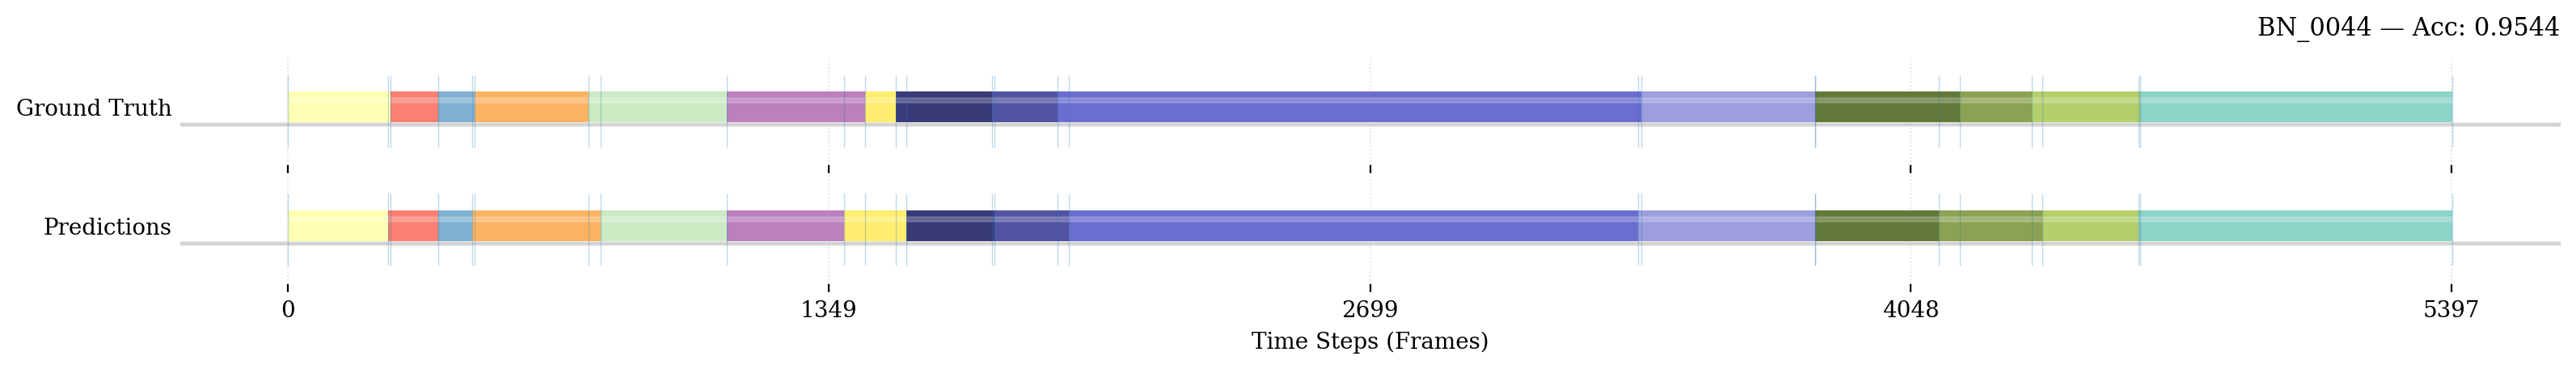

/tmp/ipykernel_359009/218592891.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.15)


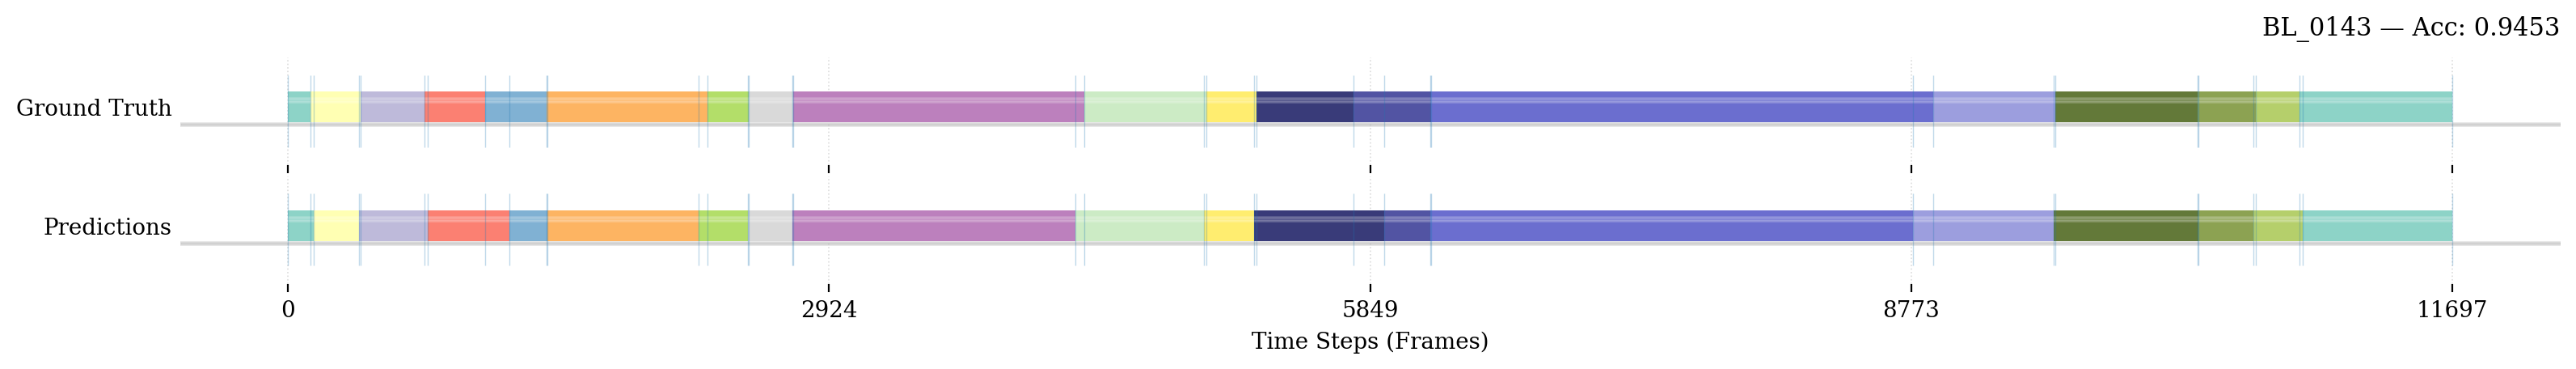

/tmp/ipykernel_359009/218592891.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.15)


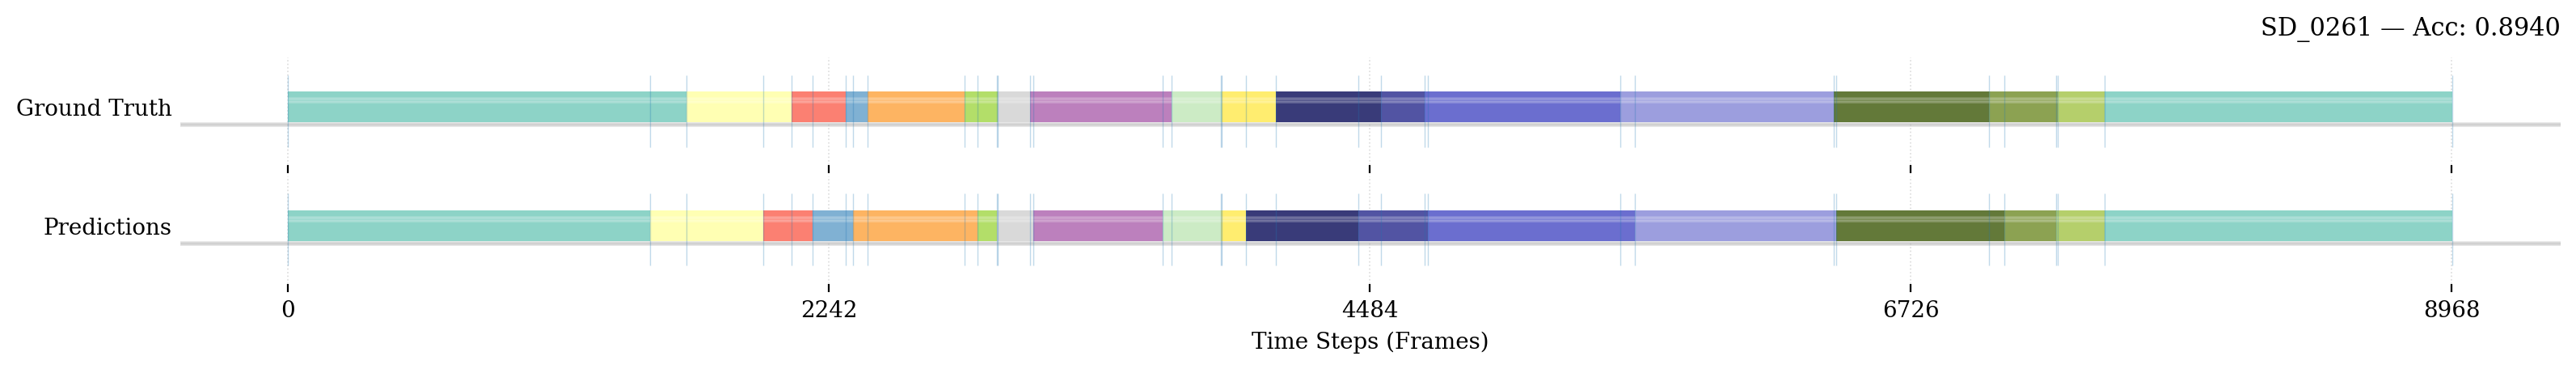

/tmp/ipykernel_359009/218592891.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.15)


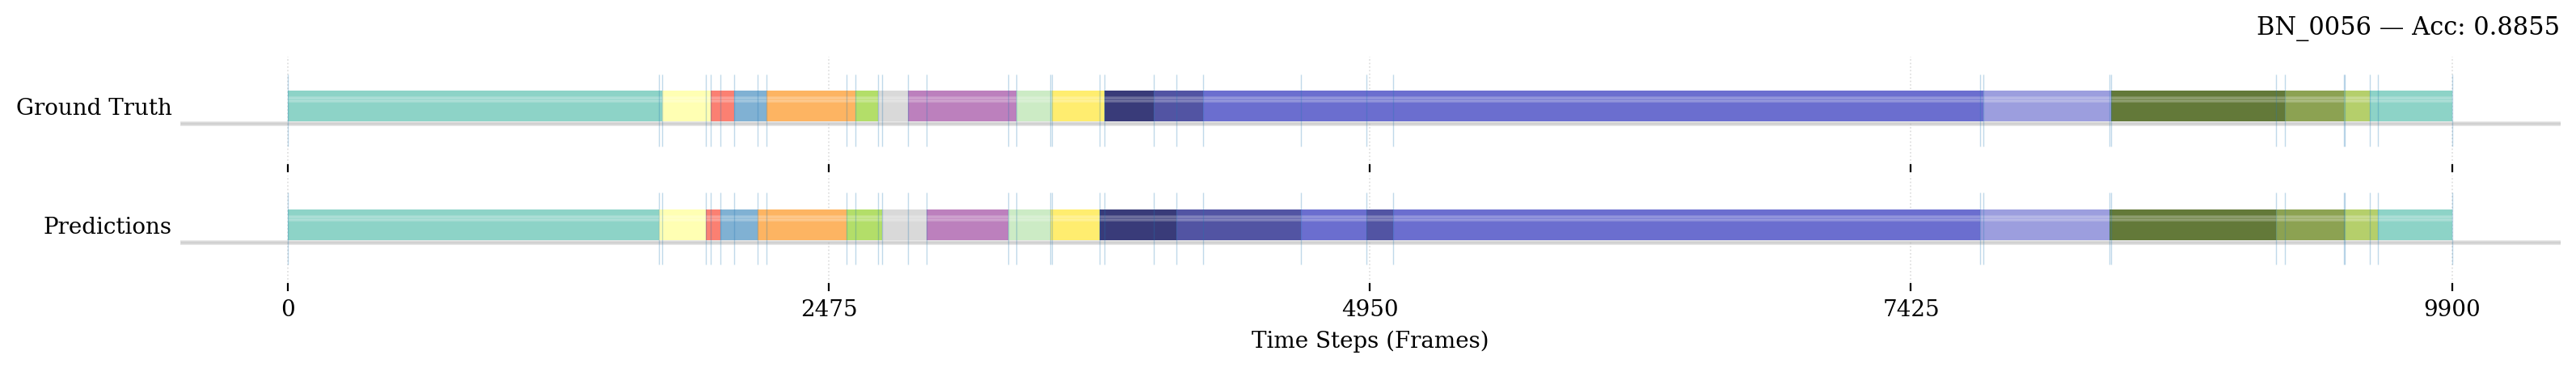

/tmp/ipykernel_359009/218592891.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.15)


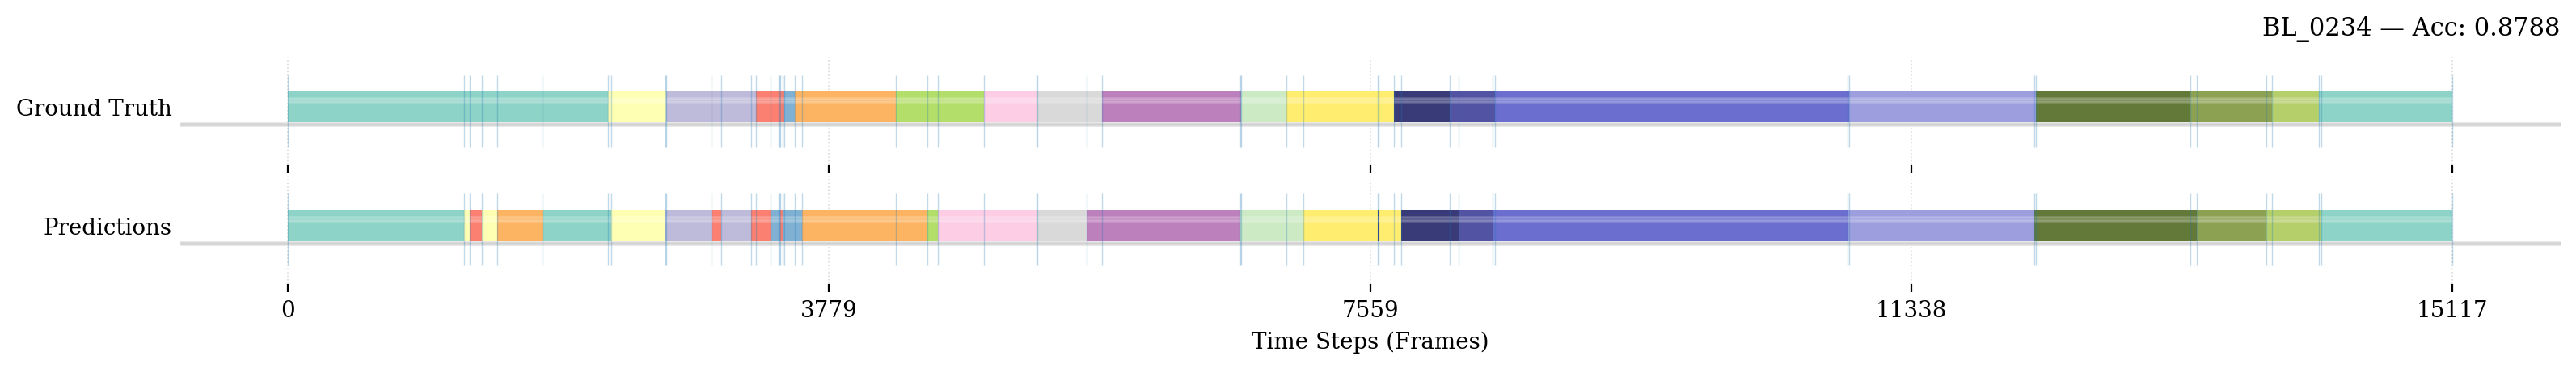

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from matplotlib import rcParams

# --- font setup ---
rcParams.update({
    "text.usetex": False,
    "font.family": "serif",        # generic serif
    "font.serif": ["CMU Serif", "DejaVu Serif", "serif"],  # fallback chain
    "font.size": 10,
})

def _segments_from_labels(labels):
    labels = np.asarray(labels, dtype=int).ravel()
    change = np.flatnonzero(np.r_[True, labels[1:] != labels[:-1]])
    ends = np.r_[change[1:], len(labels)]
    return [(int(s), int(e - s), int(labels[s])) for s, e in zip(change, ends)]

def _make_id2color(num_classes, palettes=("Set3", "tab20b", "tab20c")):
    colors = []
    for name in palettes:
        k = 12 if name.lower() == "set3" else 20
        cmap = get_cmap(name, k)
        colors.extend([cmap(i) for i in range(k)])
    if num_classes > len(colors):
        hsv = get_cmap("hsv", num_classes + 1)
        colors = [hsv(i) for i in range(num_classes)]
    return {i: colors[i] for i in range(num_classes)}

id2color = _make_id2color(model.num_classes)

for video_id in selected_videos:
    if video_id not in all_results:
        continue

    r = all_results[video_id]
    gt   = np.asarray(r['gt_sequence'], dtype=int)
    pred = np.asarray(r['pred_sequence'], dtype=int)
    L    = int(r['length'])
    acc  = float(r['accuracy'])

    gt = gt[:L]; pred = pred[:L]
    gt_segs   = _segments_from_labels(gt)
    pred_segs = _segments_from_labels(pred)

    fig, axs = plt.subplots(
        2, 1, sharex=True, figsize=(16, 2.0), dpi=200,
        gridspec_kw=dict(hspace=0.10, top=0.95, bottom=0.25, left=0.06, right=0.98)
    )
    fig.patch.set_alpha(0)
    for ax in axs:
        ax.set_facecolor("none")

    rows = [(axs[0], gt_segs, "Ground Truth"),
            (axs[1], pred_segs, "Predictions")]

    band_y, band_h = 0.42, 0.30

    for ax, segs, ylabel in rows:
        for start, length, cid in segs:
            ax.broken_barh([(start, length)], (band_y, band_h),
                           facecolors=id2color[cid], edgecolor="none", zorder=2)
        ax.axhspan(band_y + band_h*0.65, band_y + band_h*0.78,
                   color="white", alpha=0.18, zorder=3)
        ax.axhspan(band_y - band_h*0.10, band_y - band_h*0.02,
                   color="black", alpha=0.10, zorder=1)

        ax.set_ylim(0, 1.05)
        ax.set_yticks([band_y + band_h/2])
        ax.set_yticklabels([ylabel])
        ax.spines[['top','right','left','bottom']].set_visible(False)
        ax.tick_params(axis='y', length=0)
        ax.grid(axis='x', linestyle=':', linewidth=0.6, alpha=0.45, zorder=0)

    boundaries = {0, L}
    for s, l, _ in gt_segs + pred_segs:
        boundaries.add(s); boundaries.add(s + l)
    for ax in axs:
        ax.vlines(sorted(boundaries), ymin=0.18, ymax=0.88,
                  linewidth=0.5, alpha=0.28, zorder=4)

    q = [0, L//4, L//2, 3*L//4, L-1]
    axs[1].set_xticks(q)
    axs[1].set_xticklabels([str(v) for v in q])
    axs[1].set_xlabel("Time Steps (Frames)", fontsize=10)

    # video id + accuracy top-right
    axs[0].text(1.0, 1.15,
                f"{video_id} — Acc: {acc:.4f}",
                transform=axs[0].transAxes,
                ha="right", va="bottom", fontsize=11)

    plt.tight_layout(pad=0.15)
    plt.show()


In [9]:
# Save comprehensive results to CSV files
print("\n💾 Saving comprehensive results...")

# Create output directory
output_dir = Path('visualization_outputs')
output_dir.mkdir(exist_ok=True)

# Save summary results
import pandas as pd
summary_data = []
for video_id, result in all_results.items():
    summary_data.append({
        'video_id': video_id,
        'length': result['length'],
        'accuracy': result['accuracy'],
        'gt_phases': str(list(result['gt_phases'])),
        'pred_phases': str(list(result['pred_phases']))
    })

summary_df = pd.DataFrame(summary_data)
summary_path = output_dir / 'validation_summary.csv'
summary_df.to_csv(summary_path, index=False)
print(f"✓ Summary saved to: {summary_path}")

# Save detailed results for TOP performing videos
for video_id in selected_videos:
    if video_id in all_results:
        result = all_results[video_id]
        detailed_df = pd.DataFrame({
            'time_step': range(result['length']),
            'ground_truth': result['gt_sequence'],
            'prediction': result['pred_sequence'],
            'correct': result['gt_sequence'] == result['pred_sequence']
        })
        
        detailed_path = output_dir / f'{video_id}_detailed_analysis.csv'
        detailed_df.to_csv(detailed_path, index=False)
        print(f"✓ Detailed analysis for {video_id} saved to: {detailed_path}")

print(f"\n✓ All results saved to {output_dir}/")
print(f"\n🎯 Analysis Summary:")
print(f"  - Total videos processed: {len(all_results)}")
print(f"  - Top 5 videos selected for visualization: {selected_videos}")
print(f"  - Visualization success: {'✅ Yes' if visualization_success else '❌ No'}")
print(f"  - Average accuracy: {np.mean(accuracies):.4f} ({np.mean(accuracies)*100:.2f}%)")
print(f"\n🎉 Multi-video analysis completed successfully!")


💾 Saving comprehensive results...
✓ Summary saved to: visualization_outputs/validation_summary.csv
✓ Detailed analysis for BN_0044 saved to: visualization_outputs/BN_0044_detailed_analysis.csv
✓ Detailed analysis for BL_0143 saved to: visualization_outputs/BL_0143_detailed_analysis.csv
✓ Detailed analysis for SD_0261 saved to: visualization_outputs/SD_0261_detailed_analysis.csv
✓ Detailed analysis for BN_0056 saved to: visualization_outputs/BN_0056_detailed_analysis.csv
✓ Detailed analysis for BL_0234 saved to: visualization_outputs/BL_0234_detailed_analysis.csv

✓ All results saved to visualization_outputs/

🎯 Analysis Summary:
  - Total videos processed: 15
  - Top 5 videos selected for visualization: ['BN_0044', 'BL_0143', 'SD_0261', 'BN_0056', 'BL_0234']


NameError: name 'visualization_success' is not defined